# CardioIA · Assistente Cardiológico Virtual
Selecione um exemplo reservado e um modelo. A saída compara a classificação com o rótulo ChestMNIST. Seis imagens públicas foram selecionadas por sorteio com semente fixa, três por rótulo. Uso acadêmico com escores sem calibração clínica.

A opção CNN com mais negativos usa o modelo da análise complementar. A CNN de referência sinalizou mais positivos; a candidata produziu menos falsos alarmes no teste comparativo. Cada modelo usa o próprio limiar.

In [1]:
from pathlib import Path
import subprocess
import sys

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fase4/src").is_dir()), None)
if raiz is None:
    raiz = Path.cwd() / "cardioia-fase4-revisao"
    if not (raiz / "fase4/src").is_dir():
        subprocess.run(["git", "clone", "--branch", "fase4", "--depth", "1",
                        "https://github.com/marcus-vlgarcia/cardioia.git", str(raiz)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(raiz / "fase4/requirements.txt")], check=True)
sys.path.insert(0, str(raiz / "fase4/src"))


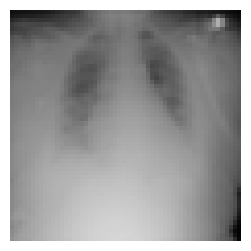

Referência da base: Com rótulo de cardiomegalia
Classificação simulada: Sem rótulo de cardiomegalia
Escore positivo: 0.416 · Limiar: 0.508


In [2]:
from functools import lru_cache
from dados import CLASSES, RESULTADOS, preparar_imagem
from PIL import Image
from modelos import carregar_prototipo
import matplotlib.pyplot as plt
import numpy as np
import torch

with np.load(RESULTADOS / "amostras_demo.npz", allow_pickle=False) as exemplos_salvos:
    imagens, rotulos, indices = (exemplos_salvos[c] for c in ("imagens", "rotulos", "indices"))
exemplos = {f"Exame {indice} · {CLASSES[rotulo]}": i
            for i, (indice, rotulo) in enumerate(zip(indices, rotulos))}

@lru_cache(maxsize=3)
def carregar(nome):
    return carregar_prototipo(RESULTADOS, nome)

def demonstrar(modelo, indice):
    imagem = preparar_imagem(Image.fromarray(imagens[indice]))
    rotulo = rotulos[indice]
    inferir, limiar = carregar(modelo)
    with torch.inference_mode():
        escore = inferir(imagem[None]).sigmoid().item()
    plt.figure(figsize=(3, 3))
    plt.imshow(imagem[0], cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.show()
    print(f"Referência da base: {CLASSES[rotulo]}")
    print(f"Classificação simulada: {CLASSES[int(escore >= limiar)]}")
    print(f"Escore positivo: {escore:.3f} · Limiar: {limiar:.3f}")

demonstrar("cnn", 3)

In [3]:
import ipywidgets as widgets
try:
    from google.colab import output
except ImportError:
    pass
else:
    output.enable_custom_widget_manager()
widgets.interact(
    demonstrar,
    modelo=widgets.Dropdown(options=[("CNN do zero", "cnn"), ("ResNet18", "resnet18"),
                                    ("CNN com mais negativos", "cnn_ampliada")],
                            description="Modelo"),
    indice=widgets.Dropdown(options=list(exemplos.items()), description="Exemplo"),
);

interactive(children=(Dropdown(description='Modelo', options=(('CNN do zero', 'cnn'), ('ResNet18', 'resnet18')…